# Suppose you are working in a data-driven job role, and you hava to answer all these question.
# 1. First write a code where, by changing just the keyword, we can search for multiple thing.
# 2. Top 15 countries where the keywords are searched the most and also create visual representation.
# 3. A world map needs  to be plotted showing the countries that search the keyword the most.
# 4. We need to extract the time-wise interest of the keyword - hpw it trended in different years.
# 5. Compare related keyword and plot the graph.

In [20]:
pip install pandas matplotlib pytrends seaborn plotly

Note: you may need to restart the kernel to use updated packages.


In [19]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from pytrends.request import TrendReq



# setup pytrend library and keyword define

In [54]:
pytrends = TrendReq(hl = 'en-US' , tz = 360)
keyword = "Data science"


# Data Request

In [55]:
pytrends.build_payload([keyword], cat = 0, timeframe = 'today 12-m' , geo='', gprop = '')

# Country wise interest

In [56]:
region_data = pytrends.interest_by_region()
region_data = region_data.sort_values(by = keyword, ascending = False).head(15)

C:\Users\rahul\AppData\Local\Temp\ipykernel_10312\1295936991.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x = region_data[keyword], y = region_data.index, palette = "Blues_d")


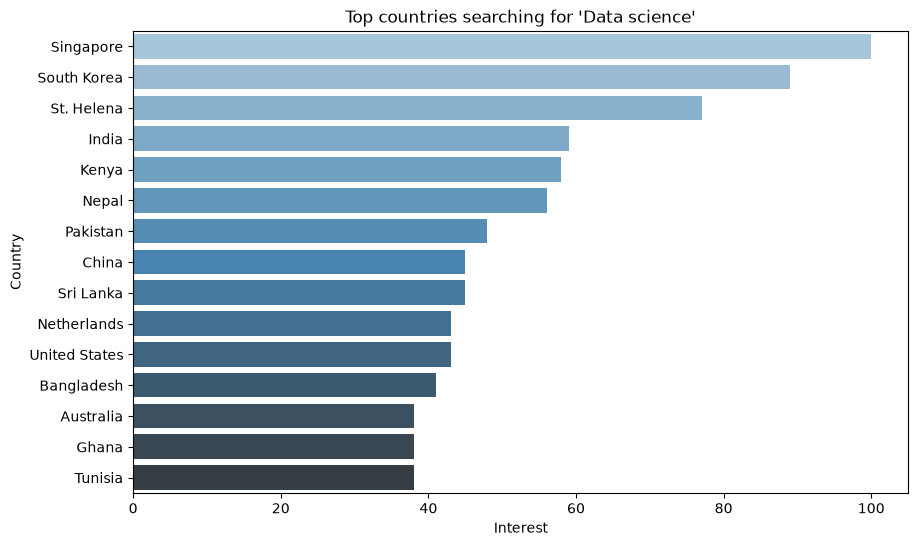

In [57]:
plt.figure(figsize =(10,6))
sns.barplot(x = region_data[keyword], y = region_data.index, palette = "Blues_d")
plt.title(f"Top countries searching for '{keyword}'")
plt.xlabel("Interest")
plt.ylabel("Country")
plt.show()

# World Map

C:\Users\rahul\AppData\Local\Temp\ipykernel_10312\1056842664.py:2: DeprecationWarning: The library used by the *country names* `locationmode` option is changing in an upcoming version. Country names in existing plots may not work in the new version. To ensure consistent behavior, consider setting `locationmode` to *ISO-3*.
  fig=px.choropleth(region_data,


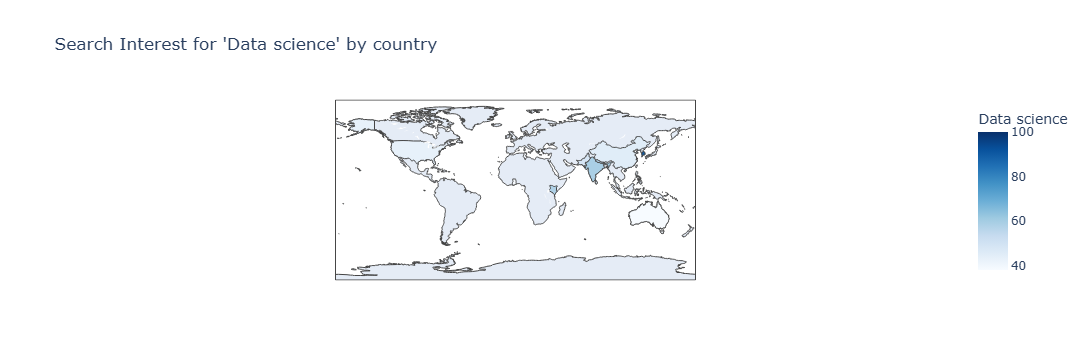

In [58]:
region_data = region_data.reset_index()
fig=px.choropleth(region_data,
                  locations = 'geoName',
                  locationmode= 'country names',
                  color=keyword, 
                 title= f"Search Interest for '{keyword}' by country",
                  color_continuous_scale='Blues')
fig.show()

# Time Wise Interest

In [59]:
time_df = pytrends.interest_over_time()

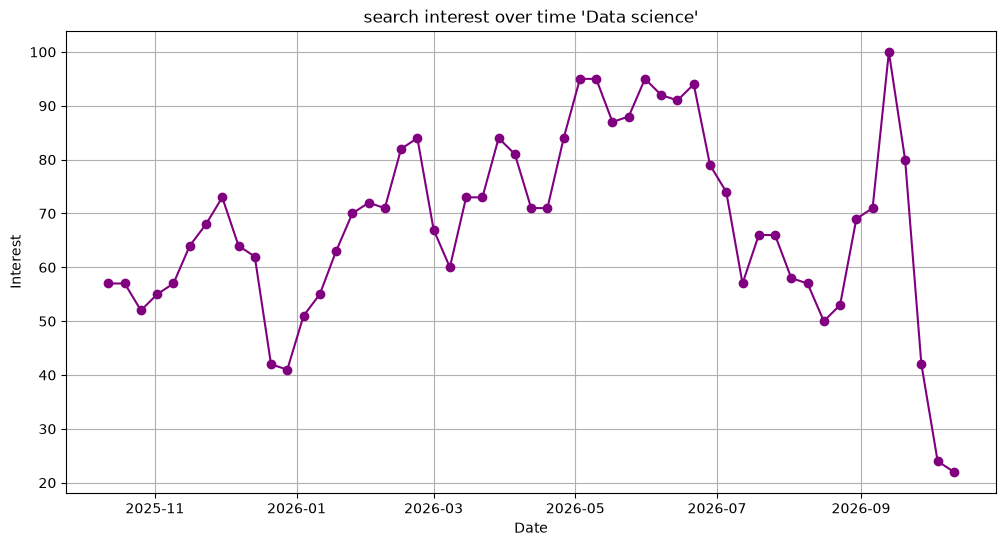

In [60]:
plt.figure(figsize = (12,6))
plt.plot(time_df.index, time_df[keyword], marker = 'o', color = 'purple')
plt.title(f"search interest over time '{keyword}'")
plt.xlabel("Date")
plt.ylabel("Interest")
plt.grid(True)
plt.show()

In [61]:
kw_list = ["Artificial Intelligence", "data science", "machine learning"]
pytrends.build_payload(kw_list, cat=0, timeframe= 'today 12-m', geo='', gprop='')

AttributeError: module 'matplotlib.pyplot' has no attribute 'xlable'

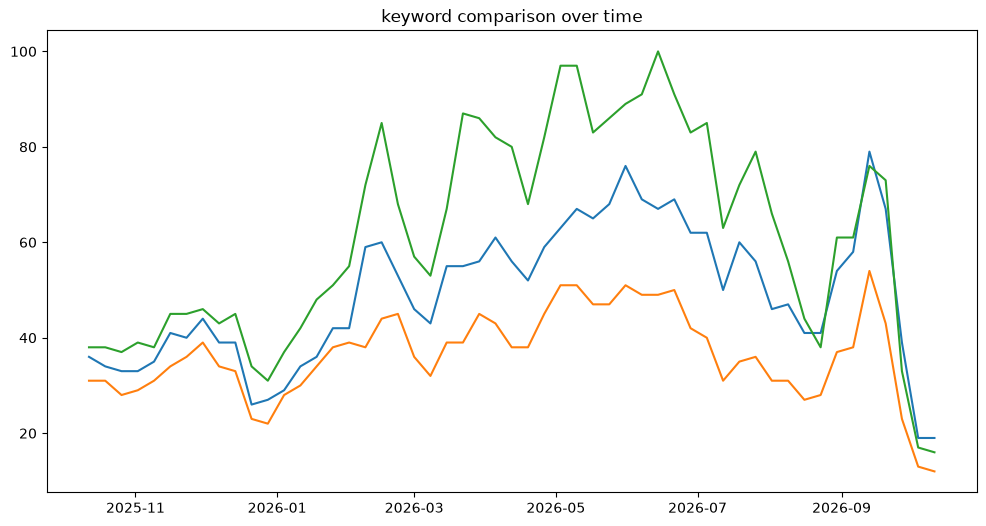

In [62]:
compare_df = pytrends.interest_over_time()
plt.figure(figsize=(12,6))
for kw in kw_list:
    plt.plot(compare_df.index, compare_df[kw], label = kw )

plt.title("keyword comparison over time")
plt.xlable("Date")
plt.ylable("Interest")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()